In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
x= np.linspace(-5,5,100)
y= np.sqrt(10**2-x**2)

y=np.hstack([y,-y])
x=np.hstack([x,-x])

In [3]:
x1=np.linspace(-5,5,100)
y1=np.sqrt(5**2-x1**2)
y1=np.hstack([y1,-y1])
x1=np.hstack([x1,-x1])

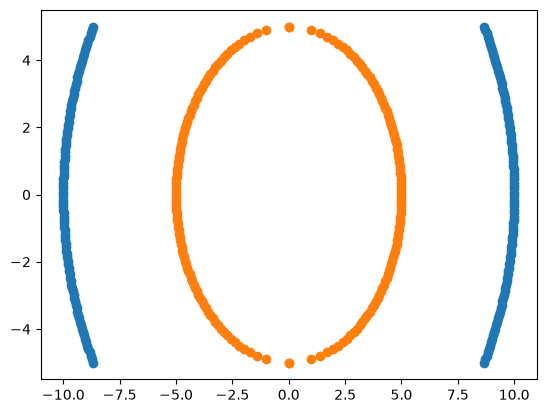

In [4]:
plt.scatter(y,x)
plt.scatter(y1,x1)
plt.show()

In [5]:
import pandas as pd

df1=pd.DataFrame(np.vstack([y,x]).T,columns=["X1","X2"])
df2=pd.DataFrame(np.vstack([y1,x1]).T,columns=["X1","X2"])

df1["Y"]=0
df2["Y"]=1

df=pd.concat([df1,df2],ignore_index=True)

In [6]:
df.head()

,X1,X2,Y
0,8.660254,-5.00000,0
1,8.717792,-4.89899,0
2,8.773790,-4.79798,0
3,8.828277,-4.69697,0
4,8.881281,-4.59596,0


In [7]:
df.tail()

,X1,X2,Y
395,-1.969049,-4.59596,1
396,-1.714198,-4.69697,1
397,-1.406908,-4.79798,1
398,-0.999949,-4.89899,1
399,-0.000000,-5.00000,1


In [8]:
# independent and dependent features 
X= df.iloc[:,:2]
y=df.Y

In [9]:
y


0      0
1      0
2      0
3      0
4      0
      ..
395    1
396    1
397    1
398    1
399    1
Name: Y, Length: 400, dtype: int64

In [10]:
# train test split
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=5)

In [11]:
y_train

249    1
42     0
297    1
127    0
56     0
      ..
73     0
118    0
189    0
206    1
355    1
Name: Y, Length: 320, dtype: int64

# polynomial kernel

K(x,y) = (X transpose * y + c )power d

In [14]:
# we need to find componenets for polynomial kernel

## X1 , X2 ,X1_SQUARE , X2_SQUARE , X1*X2

df["X1_SQUARE"]=df["X1"]**2
df["X2_SQUARE"]=df["X2"]**2
df["X1*X2"]=df["X1"]*df["X2"]
df.head()

,X1,X2,Y,X1_SQUARE,X2_SQUARE,X1*X2
0,8.660254,-5.00000,0,75.000000,25.000000,-43.301270
1,8.717792,-4.89899,0,75.999898,24.000102,-42.708375
2,8.773790,-4.79798,0,76.979390,23.020610,-42.096467
3,8.828277,-4.69697,0,77.938476,22.061524,-41.466150
4,8.881281,-4.59596,0,78.877155,21.122845,-40.818009


In [15]:
df.head()

,X1,X2,Y,X1_SQUARE,X2_SQUARE,X1*X2
0,8.660254,-5.00000,0,75.000000,25.000000,-43.301270
1,8.717792,-4.89899,0,75.999898,24.000102,-42.708375
2,8.773790,-4.79798,0,76.979390,23.020610,-42.096467
3,8.828277,-4.69697,0,77.938476,22.061524,-41.466150
4,8.881281,-4.59596,0,78.877155,21.122845,-40.818009


In [16]:
# separating independent and dependent features 
X=df[["X1","X2","X1_SQUARE","X2_SQUARE","X1*X2"]]
y=df["Y"]

In [17]:
y

0      0
1      0
2      0
3      0
4      0
      ..
395    1
396    1
397    1
398    1
399    1
Name: Y, Length: 400, dtype: int64

In [18]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=0)

In [19]:
X_train

,X1,X2,X1_SQUARE,X2_SQUARE,X1*X2
250,4.999745,0.050505,24.997449,0.002551,0.252512
63,9.906589,1.363636,98.140496,1.859504,13.508984
312,-3.263736,3.787879,10.651974,14.348026,-12.362637
159,-9.953852,-0.959596,99.079176,0.920824,9.551676
283,3.680983,3.383838,13.549638,11.450362,12.455852
...,...,...,...,...,...
323,-4.223140,2.676768,17.834915,7.165085,-11.304366
192,-9.031653,-4.292929,81.570758,18.429242,38.772248
117,-9.445795,3.282828,89.223038,10.776962,-31.008922
47,9.996811,-0.252525,99.936231,0.063769,-2.524447


In [20]:
import plotly.express as px

fig=px.scatter_3d(df, x='X1', y='X2' , z='X1*X2', color='Y')

fig.show()

In [22]:
fig=px.scatter_3d(df, x='X1_SQUARE', y='X2_SQUARE' , z='X1*X2', color='Y')

fig.show()

In [24]:
from sklearn.svm import SVC

In [25]:
classifier = SVC(kernel='linear')
classifier.fit(X_train,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [26]:
y_pred = classifier.predict(X_test)

In [27]:
from sklearn.metrics import accuracy_score


print(accuracy_score(y_test,y_pred))

1.0


In [28]:
classifier = SVC(kernel='poly')
classifier.fit(X_train,y_train)

y_pred = classifier.predict(X_test)

print(accuracy_score(y_test,y_pred))

1.0


In [29]:
classifier = SVC(kernel='rbf')
classifier.fit(X_train,y_train)

y_pred = classifier.predict(X_test)

print(accuracy_score(y_test,y_pred))

1.0
